# 07 - RQ1: internal cross-validation vs held-out hospitals (Member 2, Part C)

**RQ1:** Can routine CBC features identify leukemia with high recall, and does the model still perform well at an unseen hospital?

This notebook measures the **generalization gap** (development CV minus held-out hospital) for Random Forest, with Logistic Regression from Member 1 as a reference. It then checks which factors explain the gap:
1. **Prevalence shift:** development is 33% leukemia; hospitals are about 4%. PR-AUC depends strongly on prevalence, so the drop is partly expected.
2. **Feature shift:** do the CBC values look different at the new hospitals, within the same class?
3. **Missingness shift:** do the missing-value patterns differ by hospital?

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
sys.path.insert(0, str(ROOT / "src"))
from leuko_common import FEATURES, KEY_FEATURES, SEED
from lr_pipeline import threshold_for_recall, metrics_at

FIG_DIR = ROOT / "reports" / "figures"; TAB_DIR = ROOT / "reports" / "tables"; PRED_DIR = ROOT / "reports" / "predictions"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C_RF, C_LR, C_DEV = "#2a78d6", "#eb6834", "black"
def savefig(name): plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
pd.set_option("display.width", 200)

# ---------------- SETTINGS ----------------
TARGET_RECALL = 0.90
N_BOOT = 500
N_SUBSAMPLE = 100          # repeats for prevalence-matched PR-AUC
SITES = ["D", "E", "F", "G"]

## 1. Load predictions (development OOF + held-out) for RF and LR

In [2]:
MODELS = {
    "RF": {"oof": PRED_DIR / "rf_oof_development.csv", "eval": PRED_DIR / "rf_eval_predictions.csv.gz"},
    "LR": {"oof": PRED_DIR / "lr_raw71_oof_development.csv", "eval": PRED_DIR / "lr_raw71_eval_predictions.csv.gz"},
}
oof, held, thr, dev_fold = {}, {}, {}, {}
for name, paths in MODELS.items():
    o = pd.read_csv(paths["oof"])
    pcol = "p_oof" if "p_oof" in o.columns else "p"
    oof[name] = o
    held[name] = pd.read_csv(paths["eval"])
    thr[name] = threshold_for_recall(o["y"], o[pcol], TARGET_RECALL)
    dev_fold[name] = o.assign(p=o[pcol])
    print(f"{name}: development OOF {len(o):,}, held-out {len(held[name]):,}, frozen threshold {thr[name]:.4f}")

# Cross-check: Member 1 reported the LR threshold as 0.511
print(f"LR threshold recomputed = {thr['LR']:.4f} (Member 1 reported 0.511)")

RF: development OOF 26,922, held-out 419,715, frozen threshold 0.5278
LR: development OOF 26,922, held-out 419,715, frozen threshold 0.5108
LR threshold recomputed = 0.5108 (Member 1 reported 0.511)


## 2. Generalization gap by cohort, with bootstrap 95% CIs

In [3]:
def boot_ci(y, p, n=N_BOOT, seed=SEED):
    """Stratified bootstrap of ROC-AUC and PR-AUC (resamples positives and negatives separately)."""
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y).astype(int), np.asarray(p)
    i1, i0 = np.where(y == 1)[0], np.where(y == 0)[0]
    roc, pr = np.empty(n), np.empty(n)
    for b in range(n):
        s = np.concatenate([rng.choice(i1, len(i1)), rng.choice(i0, len(i0))])
        roc[b] = roc_auc_score(y[s], p[s]); pr[b] = average_precision_score(y[s], p[s])
    return np.percentile(roc, [2.5, 97.5]), np.percentile(pr, [2.5, 97.5])

gap_rows = []
for name in MODELS:
    o, h, t = dev_fold[name], held[name], thr[name]
    # development: per-fold mean +- SD (5 folds)
    fold_roc = [roc_auc_score(g["y"], g["p"]) for _, g in o.groupby("fold")]
    fold_pr = [average_precision_score(g["y"], g["p"]) for _, g in o.groupby("fold")]
    m = metrics_at(o["y"], o["p"], t)
    gap_rows.append({"model": name, "cohort": "development (CV, OOF)", "site": "A+B+C", "n": len(o),
                     "prevalence_%": m["prevalence_%"], "ROC_AUC": np.mean(fold_roc), "ROC_AUC_CI_lo": np.nan,
                     "ROC_AUC_CI_hi": np.nan, "PR_AUC": np.mean(fold_pr), "PR_AUC_CI_lo": np.nan, "PR_AUC_CI_hi": np.nan,
                     "fold_ROC_sd": np.std(fold_roc, ddof=1), "fold_PR_sd": np.std(fold_pr, ddof=1),
                     "recall": m["recall"], "specificity": m["specificity"]})
    targets = [("internal_validation", "A+B+C", h[h["cohort"] == "internal_validation"])]
    targets += [("external_validation", s, h[(h["cohort"] == "external_validation") & (h["site"] == s)]) for s in SITES]
    targets += [("external_validation", "pooled D-G", h[h["cohort"] == "external_validation"])]
    targets += [("real_world_test", "RW", h[h["cohort"] == "real_world_test"])]
    for cohort, site, g in targets:
        m = metrics_at(g["y"], g["p"], t)
        (rlo, rhi), (plo, phi) = boot_ci(g["y"], g["p"])
        gap_rows.append({"model": name, "cohort": cohort, "site": site, "n": len(g),
                         "prevalence_%": m["prevalence_%"], "ROC_AUC": m["ROC_AUC"], "ROC_AUC_CI_lo": rlo,
                         "ROC_AUC_CI_hi": rhi, "PR_AUC": m["PR_AUC"], "PR_AUC_CI_lo": plo, "PR_AUC_CI_hi": phi,
                         "fold_ROC_sd": np.nan, "fold_PR_sd": np.nan, "recall": m["recall"], "specificity": m["specificity"]})

gap = pd.DataFrame(gap_rows)
dev_ref = gap[gap["cohort"].str.startswith("development")].set_index("model")
gap["delta_ROC_vs_dev"] = gap.apply(lambda r: dev_ref.loc[r["model"], "ROC_AUC"] - r["ROC_AUC"], axis=1)
gap["delta_PR_vs_dev"] = gap.apply(lambda r: dev_ref.loc[r["model"], "PR_AUC"] - r["PR_AUC"], axis=1)
gap.to_csv(TAB_DIR / "RQ1_generalization_gap.csv", index=False)
display(gap.round(4))

,model,cohort,site,n,prevalence_%,ROC_AUC,ROC_AUC_CI_lo,ROC_AUC_CI_hi,PR_AUC,PR_AUC_CI_lo,PR_AUC_CI_hi,fold_ROC_sd,fold_PR_sd,recall,specificity,delta_ROC_vs_dev,delta_PR_vs_dev
0,RF,"development (CV, OOF)",A+B+C,26922,33.3333,0.9816,NaN,NaN,0.9606,NaN,NaN,0.0021,0.0057,0.9000,0.9606,0.0000,0.0000
1,RF,internal_validation,A+B+C,211611,3.6945,0.9698,0.9685,0.9713,0.5590,0.5486,0.5698,NaN,NaN,0.8804,0.9455,0.0118,0.4016
2,RF,external_validation,D,30156,4.3905,0.9590,0.9541,0.9637,0.5860,0.5615,0.6110,NaN,NaN,0.8512,0.9346,0.0226,0.3747
3,RF,external_validation,E,94318,2.6994,0.9775,0.9750,0.9796,0.6313,0.6115,0.6523,NaN,NaN,0.8354,0.9691,0.0041,0.3294
4,RF,external_validation,F,20179,4.9011,0.9694,0.9665,0.9724,0.5724,0.5441,0.6034,NaN,NaN,0.8301,0.9481,0.0122,0.3882
5,RF,external_validation,G,4970,18.6117,0.9331,0.9263,0.9402,0.7271,0.7013,0.7545,NaN,NaN,0.8714,0.8618,0.0485,0.2335
6,RF,external_validation,pooled D-G,149623,3.8657,0.9720,0.9704,0.9734,0.6189,0.6048,0.6296,NaN,NaN,0.8439,0.9563,0.0096,0.3417
7,RF,real_world_test,RW,58481,3.9158,0.9740,0.9722,0.9758,0.5554,0.5347,0.5748,NaN,NaN,0.9144,0.9408,0.0077,0.4052
8,LR,"development (CV, OOF)",A+B+C,26922,33.3333,0.9678,NaN,NaN,0.9297,NaN,NaN,0.0030,0.0069,0.9000,0.9315,0.0000,0.0000
9,LR,internal_validation,A+B+C,211611,3.6945,0.9616,0.9598,0.9634,0.4912,0.4812,0.5019,NaN,NaN,0.8978,0.9146,0.0062,0.4385


## 3. Prevalence-matched PR-AUC

To separate prevalence from model quality: for each hospital, keep all leukemia records and randomly subsample non-leukemia records so prevalence matches development (33%). PR-AUC on the matched set is comparable with development PR-AUC.

In [4]:
def prevalence_matched_pr(y, p, target_prev=0.333, n=N_SUBSAMPLE, seed=SEED):
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y).astype(int), np.asarray(p)
    i1, i0 = np.where(y == 1)[0], np.where(y == 0)[0]
    n0 = min(len(i0), int(round(len(i1) * (1 - target_prev) / target_prev)))
    vals = []
    for _ in range(n):
        s = np.concatenate([i1, rng.choice(i0, n0, replace=False)])
        vals.append(average_precision_score(y[s], p[s]))
    return np.mean(vals), np.std(vals, ddof=1), n0

pm_rows = []
for name in MODELS:
    h = held[name]
    dev_pr = gap[(gap["model"] == name) & gap["cohort"].str.startswith("development")]["PR_AUC"].item()
    for cohort, site, g in [("external_validation", s, h[(h["cohort"] == "external_validation") & (h["site"] == s)]) for s in SITES] + \
                           [("external_validation", "pooled D-G", h[h["cohort"] == "external_validation"])]:
        mean_pr, sd_pr, n0 = prevalence_matched_pr(g["y"], g["p"])
        raw_pr = average_precision_score(g["y"], g["p"])
        pm_rows.append({"model": name, "site": site, "prevalence_%": 100 * g["y"].mean(), "raw PR_AUC": raw_pr,
                        "PR_AUC at 33% prevalence": mean_pr, "sd (subsamples)": sd_pr, "dev CV PR_AUC": dev_pr,
                        "gap after prevalence matching": dev_pr - mean_pr, "non-leuk records kept": n0})
pm = pd.DataFrame(pm_rows)
pm.to_csv(TAB_DIR / "RQ1_prevalence_matched_pr.csv", index=False)
display(pm.round(4))

,model,site,prevalence_%,raw PR_AUC,PR_AUC at 33% prevalence,sd (subsamples),dev CV PR_AUC,gap after prevalence matching,non-leuk records kept
0,RF,D,4.3905,0.5860,0.9165,0.0058,0.9606,0.0441,2652
1,RF,E,2.6994,0.6313,0.9528,0.0037,0.9606,0.0078,5100
2,RF,F,4.9011,0.5724,0.9192,0.0077,0.9606,0.0414,1981
3,RF,G,18.6117,0.7271,0.8467,0.0087,0.9606,0.1139,1853
4,RF,pooled D-G,3.8657,0.6189,0.9380,0.0027,0.9606,0.0226,11585
5,LR,D,4.3905,0.5256,0.9032,0.0067,0.9297,0.0265,2652
6,LR,E,2.6994,0.5212,0.9302,0.0038,0.9297,-0.0005,5100
7,LR,F,4.9011,0.5631,0.9136,0.0080,0.9297,0.0160,1981
8,LR,G,18.6117,0.6382,0.7887,0.0102,0.9297,0.1410,1853
9,LR,pooled D-G,3.8657,0.5292,0.9132,0.0033,0.9297,0.0165,11585


## 4. Feature shift: within-class comparison

Standardised mean difference (SMD, hospital minus development, divided by the development SD). Computed **within each class** so the shift is not confounded with prevalence. Missing values are excluded from the means.

In [5]:
clean = pd.read_csv(ROOT / "data" / "cleaned" / "leukoalert_cleaned.csv.gz",
                    usecols=["site", "cohort", "y"] + KEY_FEATURES)
dev_df = clean[clean["cohort"] == "development"]
smd_rows = []
for cls, cls_name in [(0, "non-leukemia"), (1, "leukemia")]:
    d = dev_df[dev_df["y"] == cls]
    for site in SITES:
        h = clean[(clean["cohort"] == "external_validation") & (clean["site"] == site) & (clean["y"] == cls)]
        for f in KEY_FEATURES:
            sd = d[f].std()
            smd_rows.append({"class": cls_name, "site": site, "feature": f,
                             "SMD (hospital - dev)": (h[f].mean() - d[f].mean()) / sd if sd > 0 else np.nan})
smd = pd.DataFrame(smd_rows)
smd_wide = smd.pivot_table(index="feature", columns=["class", "site"], values="SMD (hospital - dev)").reindex(KEY_FEATURES)
smd_wide.set_axis([f"{c[0]} | {c[1]}" for c in smd_wide.columns], axis=1).rename_axis("feature").to_csv(
    TAB_DIR / "RQ1_feature_shift_smd.csv")
display(smd_wide.round(2))

class   leukemia                   non-leukemia                  
site           D     E     F     G            D     E     F     G
feature                                                          
WBC         0.09  0.00  0.13  0.22        -0.04 -0.19 -0.07 -0.33
NEUT#       0.15 -0.04  0.06  0.15        -0.12 -0.23 -0.10 -0.31
LYMPH#      0.00  0.07  0.06  0.20         0.12  0.18  0.14 -0.01
MONO#       0.02  0.01  0.15  0.05         0.08 -0.08 -0.03 -0.15
NEUT%      -0.13 -0.12 -0.12 -0.07        -0.32 -0.26 -0.13 -0.12
LYMPH%      0.04  0.25  0.04  0.19         0.15  0.32  0.20  0.26
MONO%       0.14 -0.25  0.15 -0.23         0.45 -0.23 -0.15 -0.47
HGB        -0.43  0.04  0.17  0.14        -0.12  0.37  0.19 -0.14
RBC        -0.24  0.12  0.21  0.08         0.14  0.36  0.14 -0.19
HCT        -0.44  0.13  0.12  0.10        -0.13  0.44  0.10 -0.22
MCV        -0.61  0.06 -0.31  0.03        -0.65  0.12 -0.13 -0.04
RDW-CV      0.45 -0.07 -0.02  0.06         0.38 -0.02 -0.13  0.29
PLT         0.27  0.02  0.04  0.13         0.20  0.09  0.03 -0.15
MPV        -0.42 -0.05  0.01  0.25        -0.47 -0.05 -0.29  0.25
IG#         0.22 -0.04  0.03  0.09         0.20 -0.08  0.08 -0.02
NRBC#      -0.00 -0.02  0.03  0.05         0.05 -0.04 -0.02 -0.04

## 5. Missingness by cohort

Share of records with each key value missing. Platelet indices and the differential block follow the cleaning rules (R6, R7).

In [6]:
miss_cols = ["PDW", "MPV", "P-LCR", "PCT", "NEUT#", "LYMPH%", "MONO%", "IG#", "NE-SSC"]
miss_df = pd.read_csv(ROOT / "data" / "cleaned" / "leukoalert_cleaned.csv.gz", usecols=["cohort", "site"] + miss_cols)
miss_df["cohort_site"] = np.where(miss_df["cohort"] == "external_validation", miss_df["site"],
                                  miss_df["cohort"].map({"development": "dev A-C", "internal_validation": "int A-C",
                                                         "real_world_test": "RW"}))
miss = (miss_df.groupby("cohort_site")[miss_cols].apply(lambda g: 100 * g.isna().mean())).round(1)
miss = miss.loc[["dev A-C", "int A-C", "D", "E", "F", "G", "RW"]]
miss.to_csv(TAB_DIR / "RQ1_missingness_by_cohort.csv")
display(miss)

,PDW,MPV,P-LCR,PCT,NEUT#,LYMPH%,MONO%,IG#,NE-SSC
cohort_site,,,,,,,,,
dev A-C,13.4,13.4,13.4,13.4,2.0,2.0,2.0,2.0,2.2
int A-C,6.1,6.1,6.1,6.1,0.4,0.4,0.4,0.4,0.4
D,8.4,8.4,8.4,8.4,0.6,0.6,0.6,0.6,0.6
E,4.5,4.5,4.5,4.5,2.2,2.2,2.2,2.2,2.2
F,3.8,3.8,3.8,3.8,0.3,0.3,0.3,0.3,0.4
G,8.1,8.1,8.1,8.1,0.0,0.0,0.0,0.0,0.1
RW,5.1,5.1,5.1,5.1,0.5,0.5,0.5,0.5,0.5


## 6. Figures

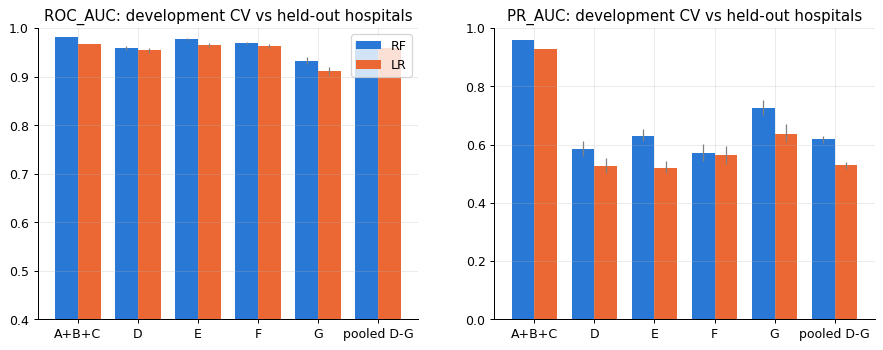

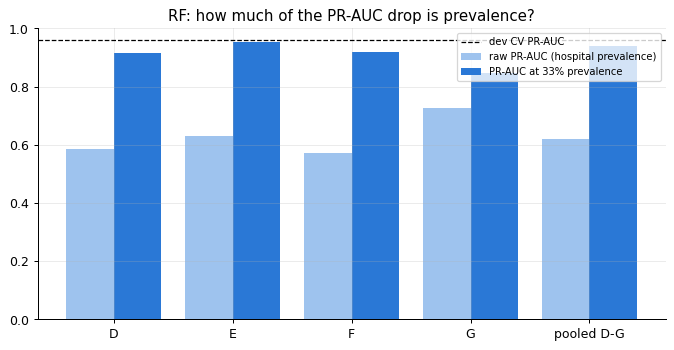

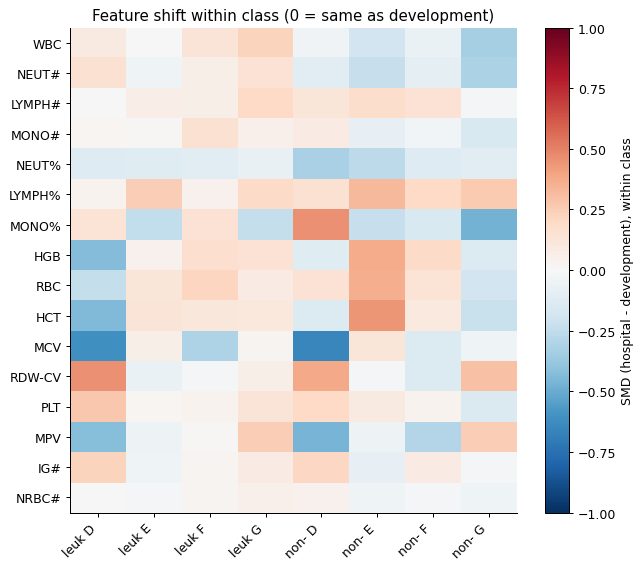

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, metric in zip(axes, ["ROC_AUC", "PR_AUC"]):
    for k, name in enumerate(MODELS):
        g = gap[(gap["model"] == name) & gap["site"].isin(["A+B+C"] + SITES + ["pooled D-G"])]
        g = g[~((g["cohort"] == "internal_validation") & (g["site"] == "A+B+C"))]
        x = np.arange(len(g)) + (k - 0.5) * 0.38
        ax.bar(x, g[metric], width=0.38, color=C_RF if name == "RF" else C_LR, label=name)
        err_lo = g[metric] - g[f"{metric}_CI_lo"].fillna(g[metric]); err_hi = g[f"{metric}_CI_hi"].fillna(g[metric]) - g[metric]
        ax.errorbar(x, g[metric], yerr=[err_lo.clip(lower=0), err_hi.clip(lower=0)], fmt="none", ecolor="grey", lw=1)
    ax.set_xticks(np.arange(len(g)), g["site"].tolist())
    ax.set_title(f"{metric}: development CV vs held-out hospitals")
    ax.set_ylim(0.4 if metric == "ROC_AUC" else 0, 1.0)
axes[0].legend()
savefig("RQ1_roc_pr_gap")

fig, ax = plt.subplots(figsize=(9, 4.2))
pmr = pm[pm["model"] == "RF"]
x = np.arange(len(pmr))
ax.bar(x - 0.2, pmr["raw PR_AUC"], 0.4, color="#9ec3ee", label="raw PR-AUC (hospital prevalence)")
ax.bar(x + 0.2, pmr["PR_AUC at 33% prevalence"], 0.4, color=C_RF, label="PR-AUC at 33% prevalence")
ax.axhline(gap[(gap["model"] == "RF") & gap["cohort"].str.startswith("development")]["PR_AUC"].item(), color="black", ls="--", lw=1, label="dev CV PR-AUC")
ax.set_xticks(x, pmr["site"].tolist()); ax.set_title("RF: how much of the PR-AUC drop is prevalence?"); ax.legend(fontsize=8)
savefig("RQ1_prevalence_matched")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(smd_wide.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(smd_wide.shape[1]), [f"{c[0][:4]} {c[1]}" for c in smd_wide.columns], rotation=45, ha="right")
ax.set_yticks(range(len(KEY_FEATURES)), KEY_FEATURES); ax.grid(False)
plt.colorbar(im, ax=ax, label="SMD (hospital - development), within class")
ax.set_title("Feature shift within class (0 = same as development)")
savefig("RQ1_feature_shift_heatmap")

## 7. Summary

In [8]:
rf_dev = gap[(gap["model"] == "RF") & gap["cohort"].str.startswith("development")].iloc[0]
rf_pool = gap[(gap["model"] == "RF") & (gap["site"] == "pooled D-G")].iloc[0]
rf_pm = pm[(pm["model"] == "RF") & (pm["site"] == "pooled D-G")].iloc[0]
# PR-AUC drop split: part explained by prevalence (raw -> 33% matched) and part left after matching (matched -> dev)
explained = (rf_pm["PR_AUC at 33% prevalence"] - rf_pool["PR_AUC"]) / (rf_dev["PR_AUC"] - rf_pool["PR_AUC"])
print(f"RF development CV : ROC-AUC {rf_dev['ROC_AUC']:.4f}  PR-AUC {rf_dev['PR_AUC']:.4f}")
print(f"RF held-out D-G   : ROC-AUC {rf_pool['ROC_AUC']:.4f} [{rf_pool['ROC_AUC_CI_lo']:.4f}, {rf_pool['ROC_AUC_CI_hi']:.4f}]  "
      f"PR-AUC {rf_pool['PR_AUC']:.4f} (prevalence {rf_pool['prevalence_%']:.1f}%)  recall {rf_pool['recall']:.3f}")
print(f"RF PR-AUC at 33% prevalence (D-G pooled): {rf_pm['PR_AUC at 33% prevalence']:.4f}")
print(f"Share of the PR-AUC drop explained by prevalence: {100 * explained:.0f}%")

RF development CV : ROC-AUC 0.9816  PR-AUC 0.9606
RF held-out D-G   : ROC-AUC 0.9720 [0.9704, 0.9734]  PR-AUC 0.6189 (prevalence 3.9%)  recall 0.844
RF PR-AUC at 33% prevalence (D-G pooled): 0.9380
Share of the PR-AUC drop explained by prevalence: 93%
